# DUNE: simplified number of $\nu_e$ appearance events

$$N = \varepsilon_\text{eff}\;P(\nu_\mu\to\nu_e;E_0,L)\;\sigma_{CC}(E_0)\;\Phi\;\mathrm{POT}\;N_T$$

Step by step: detector and exposure, flux ($\Phi$, $E_0$), cross section, oscillation probability, number of events,
effective efficiency, bi-probability plot and $\delta_{CP}$ sensitivity. Assumptions, derivations and references:
`docs/number_of_events.pdf` (short version: `docs/number_of_events_summary.pdf`). The helper functions are in
`nuosc/simple_counting.py`.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

from nuosc import NeutrinoOscillator, get_experiment
from nuosc import simple_counting as sc
from nuosc.plotting import set_style

SET_STYLE = True     # True: nuosc style (latex_style -> SciencePlots -> default); False: keep your own matplotlib settings
c = set_style(SET_STYLE)

EXP = "DUNE"
cfg, setup = get_experiment(EXP), sc.SETUP[EXP]
BEAM = {"FHC": r"$\nu$ beam", "RHC": r"$\bar\nu$ beam"}

plot style: latex_style


## 1. Detector and exposure

In [16]:
print(f"baseline L = {cfg['baseline']} km, matter density = {cfg['rho']} g/cm^3")
print(f"target: {setup['target']}, fiducial mass M = {setup['M_kt']} kt   ({setup['status']})")
NT = setup["M_kt"] * 1e9 * sc.N_A
print(f"N_T = M [g] x N_A = {setup['M_kt']}e9 g x {sc.N_A:.4e} /g = {NT:.3e} nucleons")
for m in sc.MODES:
    print(f"POT ({m}, {'antineutrino' if sc.MODES[m] else 'neutrino'} beam) = {setup['POT'][m]:.3e}")
print("references:", setup["refs"])

baseline L = 1300.0 km, matter density = 2.848 g/cm^3
target: liquid argon, fiducial mass M = 40.0 kt   (projected: 6.5+6.5 yr at 1.2 MW)
N_T = M [g] x N_A = 40.0e9 g x 6.0221e+23 /g = 2.409e+34 nucleons
POT (FHC, neutrino beam) = 7.150e+21
POT (RHC, antineutrino beam) = 7.150e+21
references: DUNE TDR configuration, arXiv:2103.04797


## 2. Flux: $\Phi$ and $E_0$

Unoscillated flux at the far detector, $d\Phi/dE$ in $\nu\,\mathrm{cm^{-2}\,GeV^{-1}\,POT^{-1}}$ (converted from the
units of the original file). Shaded: main peak of the beam (flux above 10 % of its maximum), whose flux-weighted mean
energy is $E_0$. $\Phi$ is the integral of the **whole** $\nu_\mu$ ($\bar\nu_\mu$) spectrum,
$\Phi = \sum_k (d\Phi/dE)_k\,\Delta E_k$.

source: DUNE TDR far-detector flux (arXiv:2103.04797)


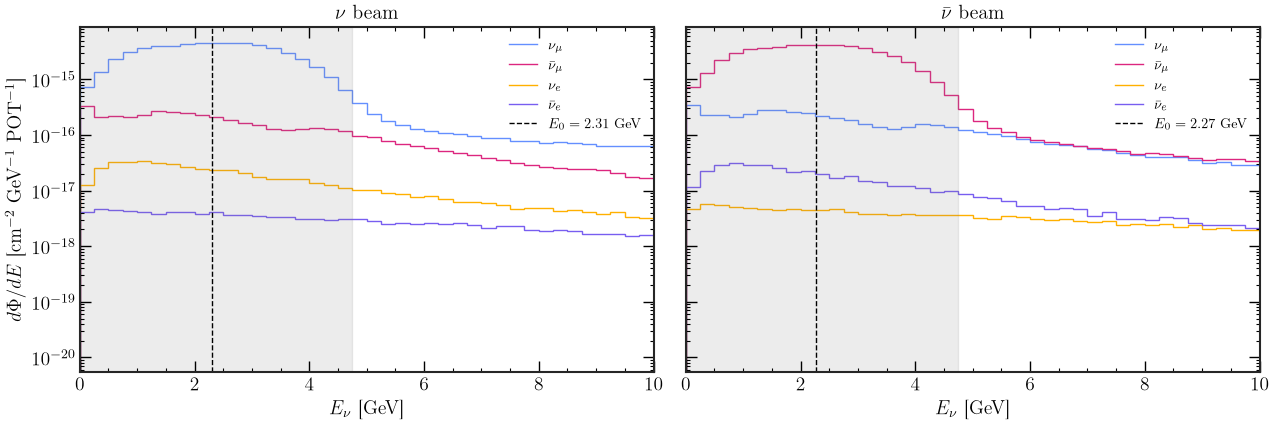

FHC: Phi = sum_k (dPhi/dE)_k dE_k = 1.5480e-14 cm^-2 POT^-1 (numu), E0 = 2.31 GeV (mean over the whole spectrum: 2.88 GeV)
      neglected in the pure-beam approximation: wrong sign 7.4 %, intrinsic nue + nuebar 1.1 % of the total flux
RHC: Phi = sum_k (dPhi/dE)_k dE_k = 1.3845e-14 cm^-2 POT^-1 (numubar), E0 = 2.27 GeV (mean over the whole spectrum: 2.59 GeV)
      neglected in the pure-beam approximation: wrong sign 9.9 %, intrinsic nue + nuebar 1.1 % of the total flux


In [ ]:
print("source:", sc.FLUX_REFS[EXP])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ING = {}
for ax, m in zip(axes, sc.MODES):
    for i, (fl, lab) in enumerate((("numu", r"$\nu_\mu$"), ("numubar", r"$\bar\nu_\mu$"),
                                    ("nue", r"$\nu_e$"), ("nuebar", r"$\bar\nu_e$"))):
        e, v = sc.flux_hist(EXP, m, fl)
        ax.stairs(v, e, color=c[i], label=lab)
    g = ING[m] = sc.ingredients(EXP, m)
    ax.axvspan(*g["E_peak_range"], color="gray", alpha=0.15)
    ax.axvline(g["E0"], color="k", ls="--", lw=1, label=rf"$E_0 = {g['E0']:.2f}$ GeV")
    ax.set_yscale("log")
    ax.set_xlim(0, 4 * cfg["E_peak"] if EXP != "DUNE" else 10)
    ax.set_xlabel(r"$E_\nu$ [GeV]")
    ax.set_title(BEAM[m])
    ax.legend(fontsize="small")
axes[0].set_ylabel(r"$d\Phi/dE$ [cm$^{-2}$ GeV$^{-1}$ POT$^{-1}$]")
plt.tight_layout()
plt.show()
for m, g in ING.items():
    fl = sc.beam_flavour(m)
    e, v = sc.flux_hist(EXP, m, fl)
    print(f"{m}: Phi = sum_k (dPhi/dE)_k dE_k = {np.sum(v * np.diff(e)):.4e} cm^-2 POT^-1 ({fl}),"
          f" E0 = {g['E0']:.2f} GeV (mean over the whole spectrum: {g['E_mean_all']:.2f} GeV)")
    F = {f: sc.integrated_flux(EXP, m, f) for f in ("numu", "numubar", "nue", "nuebar")}
    tot = sum(F.values())
    wrong = F["numubar" if m == "FHC" else "numu"]
    print(f"      neglected in the pure-beam approximation: wrong sign {100 * wrong / tot:.1f} %, "
          f"intrinsic nue + nuebar {100 * (F['nue'] + F['nuebar']) / tot:.1f} % of the total flux")

## 3. Cross section

Inclusive CC cross section per nucleon of the table used for this experiment; dotted: deep-inelastic limit
($\sigma/E\to0.67$ and $0.34\times10^{-38}\,\mathrm{cm^2/GeV}$, Formaggio & Zeller, RMP 84 (2012) 1307).

table: GENIE 2.12 on argon, DUNE TDR configuration (arXiv:2103.04797), smoothed


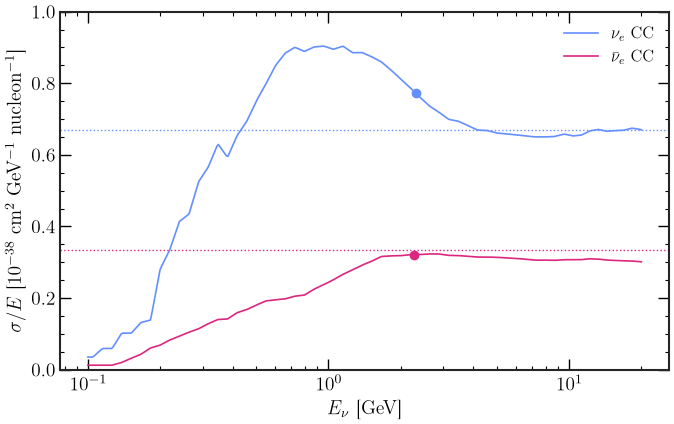

FHC: sigma(nue, E0 = 2.31 GeV) = 1.783e-38 cm^2
RHC: sigma(nuebar, E0 = 2.27 GeV) = 7.288e-39 cm^2


In [18]:
print("table:", sc.XS_REFS[setup["xs"]])
E = np.logspace(-1, np.log10(20), 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (fl, lab) in enumerate((("nue", r"$\nu_e$ CC"), ("nuebar", r"$\bar\nu_e$ CC"))):
    ax.plot(E, sc.sigma_cc(E, fl, setup["xs"]) / E / 1e-38, color=c[i], label=lab)
    m = "RHC" if "bar" in fl else "FHC"
    ax.plot(ING[m]["E0"], ING[m]["sigma"] / ING[m]["E0"] / 1e-38, "o", color=c[i])
ax.axhline(0.67, color=c[0], ls=":", lw=1)
ax.axhline(0.335, color=c[1], ls=":", lw=1)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel(r"$E_\nu$ [GeV]")
ax.set_ylabel(r"$\sigma/E$ [$10^{-38}$ cm$^2$ GeV$^{-1}$ nucleon$^{-1}$]")
ax.legend()
plt.tight_layout()
plt.show()
for m, g in ING.items():
    print(f"{m}: sigma({'nuebar' if sc.MODES[m] else 'nue'}, E0 = {g['E0']:.2f} GeV) = {g['sigma']:.3e} cm^2")

## 4. Oscillation probability

$P(\nu_\mu\to\nu_e)$ in matter (NuFast) at the NuFIT 6.0 best fit, for both orderings; the dashed line is $E_0$.

FHC, NO: P(E0 = 2.31 GeV) = 0.0738
FHC, IO: P(E0 = 2.31 GeV) = 0.0367
RHC, NO: P(E0 = 2.27 GeV) = 0.0178
RHC, IO: P(E0 = 2.27 GeV) = 0.0563


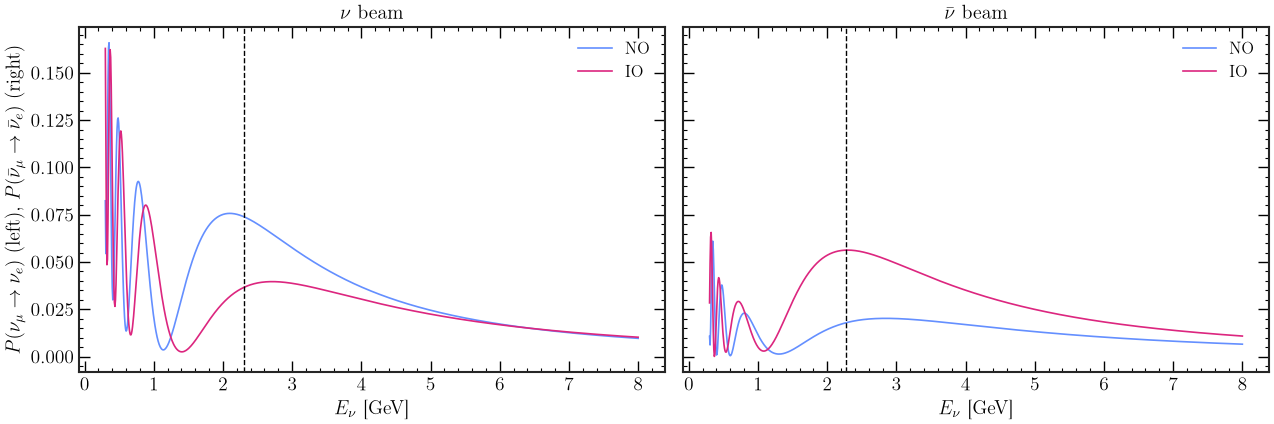

In [19]:
E = np.linspace(*cfg["E_range"], 1000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, m in zip(axes, sc.MODES):
    for i, o in enumerate(("NO", "IO")):
        osc = sc.oscillator(EXP, m, o)
        ax.plot(E, osc.matter("mu", "e", E), color=c[i], label=f"{o}")
        print(f"{m}, {o}: P(E0 = {ING[m]['E0']:.2f} GeV) = {float(osc.matter('mu', 'e', E=ING[m]['E0'])):.4f}")
    ax.axvline(ING[m]["E0"], color="k", ls="--", lw=1)
    ax.set_xlabel(r"$E_\nu$ [GeV]")
    ax.set_title(BEAM[m])
    ax.legend()
axes[0].set_ylabel(r"$P(\nu_\mu\to\nu_e)$ (left), $P(\bar\nu_\mu\to\bar\nu_e)$ (right)")
plt.tight_layout()
plt.show()

## 5. Number of events

### 5a. Effective efficiency

$\varepsilon_\text{eff}$ is fixed so that the formula, with the parameters and exposure of a published prediction,
reproduces the published number of signal events. It accounts for everything the formula leaves out (detector
efficiency and cuts, spread of the beam energy around $E_0$, cross-section differences).

In [20]:
print("reference:", sc.REF_TEXT[EXP], "\n")
EPS = sc.calibrate(EXP)
print("\neps_eff =", EPS)

reference: right-sign appearance signal of the official GLoBES configuration (arXiv:2103.04797), NuFIT 4.0 NO, delta_CP = 0 

FHC: N(eps=1) = 3493.6 at the reference parameters, N_ref = 2180.3  ->  eps_eff = 0.62
RHC: N(eps=1) = 407.6 at the reference parameters, N_ref = 437.6  ->  eps_eff = 1.07

eps_eff = {'FHC': 0.62, 'RHC': 1.07}


### 5b. The calculation, factor by factor

Pocket formula: $N_{P=1} = 60.2\,[\sigma/10^{-38}\,\mathrm{cm^2}]\,[\Phi/10^{-14}\,\mathrm{cm^{-2}POT^{-1}}]\,[\mathrm{POT}/10^{21}]\,[M/\mathrm{kt}]$,
then $\times P(E_0)$ and $\times\varepsilon_\text{eff}$. NuFIT 6.0 best fit of each ordering.

In [21]:
for o in ("NO", "IO"):
    print(f"--- {o} ---")
    for m, g in ING.items():
        N1 = 60.2 * (g["sigma"] / 1e-38) * (g["Phi"] / 1e-14) * (g["POT"] / 1e21) * g["M_kt"]
        P = float(sc.oscillator(EXP, m, o).matter("mu", "e", E=g["E0"]))
        print(f"{m}: N_P=1 = 60.2 x {g['sigma'] / 1e-38:.3f} x {g['Phi'] / 1e-14:.3f} x {g['POT'] / 1e21:.3f} x "
              f"{g['M_kt']} = {N1:.0f};  x P = {P:.4f} -> {N1 * P:.1f};  x eps = {EPS[m]} -> N = {N1 * P * EPS[m]:.1f}")

--- NO ---
FHC: N_P=1 = 60.2 x 1.783 x 1.548 x 7.150 x 40.0 = 47530;  x P = 0.0738 -> 3508.3;  x eps = 0.62 -> N = 2175.2
RHC: N_P=1 = 60.2 x 0.729 x 1.385 x 7.150 x 40.0 = 17373;  x P = 0.0178 -> 310.0;  x eps = 1.07 -> N = 331.7
--- IO ---
FHC: N_P=1 = 60.2 x 1.783 x 1.548 x 7.150 x 40.0 = 47530;  x P = 0.0367 -> 1745.1;  x eps = 0.62 -> N = 1082.0
RHC: N_P=1 = 60.2 x 0.729 x 1.385 x 7.150 x 40.0 = 17373;  x P = 0.0563 -> 977.8;  x eps = 1.07 -> N = 1046.2


## 6. Bi-probability and bi-event plots

Full $\delta_{CP}$ scan (circle: $0$, square: $90°$) at the NuFIT 6.0 best fit of each ordering. Stars: NuFIT 6.0
best fit, with the statistical error $\sqrt N$ in the event plot.

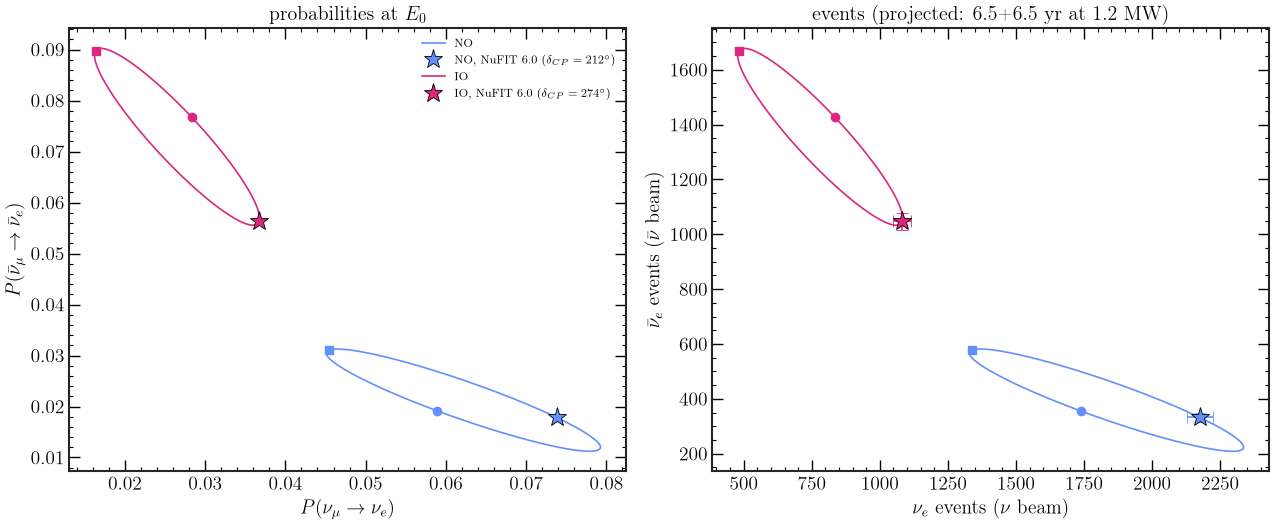

In [22]:
deltas = np.arange(0, 361, 5)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for i, o in enumerate(("NO", "IO")):
    P = np.array([[float(sc.oscillator(EXP, m, o, delta_cp=d).matter("mu", "e", E=ING[m]["E0"])) for m in sc.MODES]
                  for d in deltas])
    N = np.array([sc.counts(EXP, EPS, o, d, ING) for d in deltas])
    for ax, Z in zip(axes, (P, N)):
        ax.plot(Z[:, 0], Z[:, 1], color=c[i], label=o)
        ax.plot(*Z[0], "o", color=c[i])
        ax.plot(*Z[deltas == 90][0], "s", color=c[i])
    bf = NeutrinoOscillator(o)
    Pbf = [float(sc.oscillator(EXP, m, o).matter("mu", "e", E=ING[m]["E0"])) for m in sc.MODES]
    Nbf = sc.counts(EXP, EPS, o, bf.delta_cp, ING)
    lab = rf"{o}, NuFIT 6.0 ($\delta_{{CP}}={bf.delta_cp:.0f}^\circ$)"
    axes[0].plot(*Pbf, "*", ms=14, color=c[i], mec="k", mew=0.6, zorder=5, label=lab)
    axes[1].errorbar(*Nbf, xerr=np.sqrt(Nbf[0]), yerr=np.sqrt(Nbf[1]), fmt="*", ms=14, color=c[i], mec="k",
                     mew=0.6, capsize=4, zorder=5, label=lab)
    if EXP in sc.BF_EXP:
        p = sc.BF_EXP[EXP][o]
        Pe = [float(sc.oscillator(EXP, m, o, **p).matter("mu", "e", E=ING[m]["E0"])) for m in sc.MODES]
        Ne = [sc.n_events(EXP, m, EPS[m], o, ing=ING[m], **p) for m in sc.MODES]
        lab = rf"{o}, {sc.BF_EXP[EXP]['ref']} ($\delta_{{CP}}={p['delta_cp']:.0f}^\circ$)"
        axes[0].plot(*Pe, "D", ms=9, color=c[i], mec="k", mew=0.6, zorder=6, label=lab)
        axes[1].errorbar(*Ne, xerr=np.sqrt(Ne[0]), yerr=np.sqrt(Ne[1]), fmt="D", ms=9, color=c[i], mec="k",
                         mew=0.6, capsize=3, zorder=6)
axes[0].set_xlabel(r"$P(\nu_\mu\to\nu_e)$")
axes[0].set_ylabel(r"$P(\bar\nu_\mu\to\bar\nu_e)$")
axes[0].set_title(rf"probabilities at $E_0$")
axes[1].set_xlabel(r"$\nu_e$ events ($\nu$ beam)")
axes[1].set_ylabel(r"$\bar\nu_e$ events ($\bar\nu$ beam)")
axes[1].set_title(f"events ({setup['status']})")
axes[0].legend(fontsize="x-small")
plt.tight_layout()
plt.show()

### 6b. Seeing the ordering–$\delta_{CP}$ degeneracy

The sensitivity in section 7 is the distance, in units of $\sigma$, between the true point and the closest
CP-conserving point. Here the four CP-conserving points ($\delta_{CP}=0$: circles, $180°$: triangles, for both orderings)
are drawn on the bi-event plot, together with the true points $\delta_{CP}=90°$ (NO) and $270°$ (IO) and their
$1,2,3\sigma$ statistical contours ($\chi^2 = n^2$, i.e. ellipses with half-axes $n\sqrt{N_\nu}$, $n\sqrt{N_{\bar\nu}}$).

* solid black line: closest CP-conserving point **with the same ordering** (ordering known);
* dashed line: closest CP-conserving point **of any ordering** (ordering unknown).

When the dashed line goes to the other ordering's ellipse and is shorter, the sensitivity drops: this is the "cup" in
the dashed curves of section 7.

true NO, delta = 90: ordering known -> closest ('NO', 0), 14.3 sigma;  ordering unknown -> closest ('NO', 0), 14.3 sigma
true IO, delta = 270: ordering known -> closest ('IO', 180), 13.1 sigma;  ordering unknown -> closest ('IO', 180), 13.1 sigma


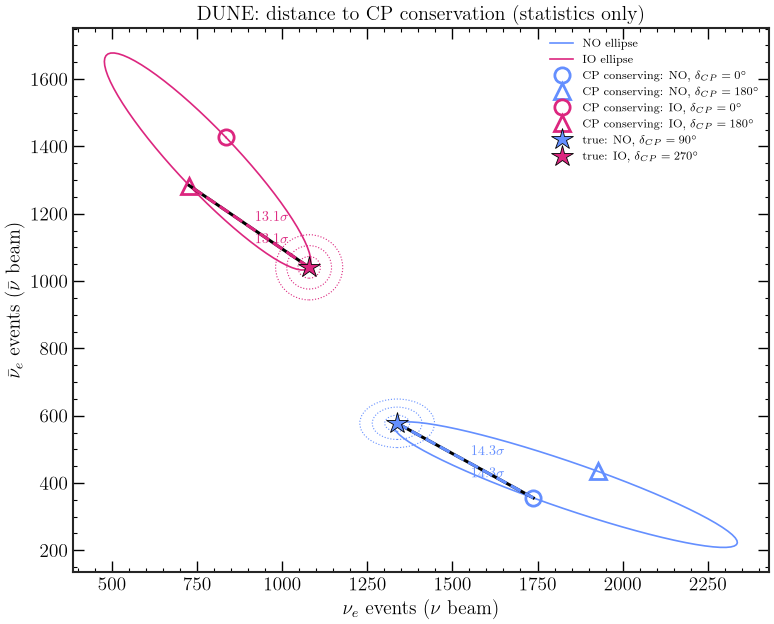

In [23]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots(figsize=(8, 6.5))
for i, o in enumerate(("NO", "IO")):
    N = np.array([sc.counts(EXP, EPS, o, d, ING) for d in deltas])
    ax.plot(N[:, 0], N[:, 1], color=c[i], label=f"{o} ellipse")
CP = {(o, d): sc.counts(EXP, EPS, o, d, ING) for o in ("NO", "IO") for d in (0, 180)}
for (o, d), N0 in CP.items():
    i = 0 if o == "NO" else 1
    ax.plot(*N0, "o" if d == 0 else "^", ms=11, mfc="none", mec=c[i], mew=2,
            label=rf"CP conserving: {o}, $\delta_{{CP}}={d}^\circ$")

for i, (o, d) in enumerate((("NO", 90), ("IO", 270))):
    Nt = sc.counts(EXP, EPS, o, d, ING)
    ax.plot(*Nt, "*", ms=16, color=c[i], mec="k", mew=0.6, zorder=6, label=rf"true: {o}, $\delta_{{CP}}={d}^\circ$")
    for n in (1, 2, 3):
        ax.add_patch(Ellipse(Nt, 2 * n * np.sqrt(Nt[0]), 2 * n * np.sqrt(Nt[1]), fill=False, color=c[i],
                             lw=0.8, ls=":", zorder=1))
    chi = {k: np.sqrt(np.sum((Nt - N0) ** 2 / Nt)) for k, N0 in CP.items()}
    same = min((k for k in chi if k[0] == o), key=chi.get)
    anyo = min(chi, key=chi.get)
    for k, ls in ((same, "-"), (anyo, "--")):
        ax.plot([Nt[0], CP[k][0]], [Nt[1], CP[k][1]], color="k" if ls == "-" else c[i], ls=ls, lw=2.2, zorder=5)
        mid = 0.5 * (Nt + CP[k])
        ax.annotate(rf"{chi[k]:.1f}$\sigma$", mid, color=c[i], fontsize="small",
                    xytext=(4, 4 if ls == "-" else -12), textcoords="offset points")
    print(f"true {o}, delta = {d}: ordering known -> closest {same}, {chi[same]:.1f} sigma;"
          f"  ordering unknown -> closest {anyo}, {chi[anyo]:.1f} sigma")
ax.set_xlabel(r"$\nu_e$ events ($\nu$ beam)")
ax.set_ylabel(r"$\bar\nu_e$ events ($\bar\nu$ beam)")
ax.set_title(f"{EXP}: distance to CP conservation (statistics only)")
ax.legend(fontsize="x-small", loc="best")
plt.tight_layout()
plt.show()

## 7. $\delta_{CP}$ sensitivity

Significance $\sqrt{\Delta\chi^2}$ to exclude $\delta_{CP}=0,\pi$ vs the true $\delta_{CP}$
(formula and derivation in `docs/number_of_events.pdf`). Left: statistics only ($f=0$); right: with a 5 %
normalization uncertainty on each sample. Solid: mass ordering known; dashed: unknown.

f = 0.00, true NO: max 15.7 sigma, fraction of delta_CP above 3 sigma: 86%
f = 0.00, true IO: max 14.6 sigma, fraction of delta_CP above 3 sigma: 85%
f = 0.05, true NO: max 9.4 sigma, fraction of delta_CP above 3 sigma: 76%
f = 0.05, true IO: max 8.7 sigma, fraction of delta_CP above 3 sigma: 73%


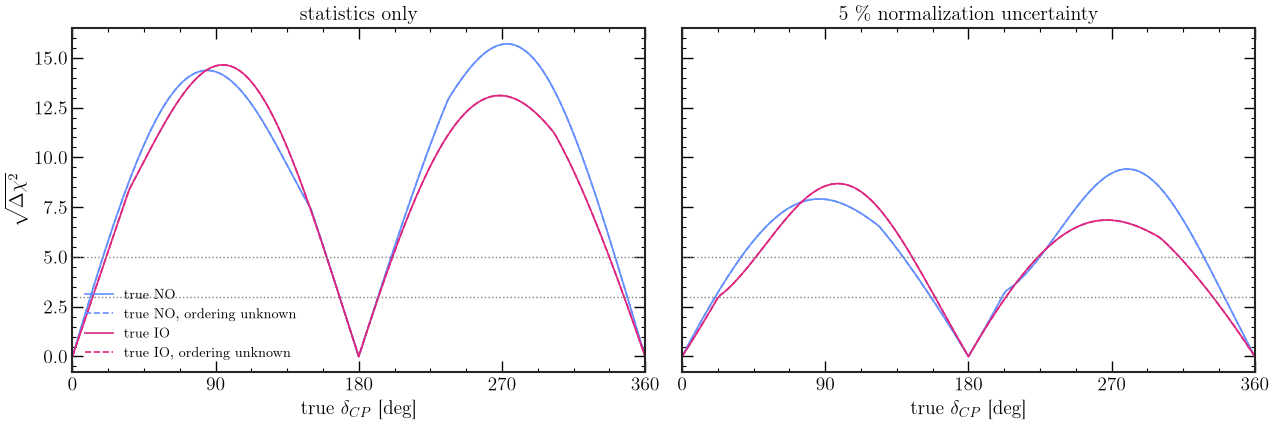

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, f in zip(axes, (0.0, 0.05)):
    for i, o in enumerate(("NO", "IO")):
        d, s = sc.cpv_sensitivity(EXP, EPS, o, f=f, ordering_known=True)
        ax.plot(d, s, color=c[i], label=f"true {o}")
        d, s2 = sc.cpv_sensitivity(EXP, EPS, o, f=f, ordering_known=False)
        ax.plot(d, s2, color=c[i], ls="--", label=f"true {o}, ordering unknown")
        print(f"f = {f:.2f}, true {o}: max {s.max():.1f} sigma, fraction of delta_CP above 3 sigma: {np.mean(s > 3):.0%}")
    for z in (3, 5):
        ax.axhline(z, color="gray", ls=":", lw=1)
    ax.set_xticks([0, 90, 180, 270, 360])
    ax.set_xlim(0, 360)
    ax.set_xlabel(r"true $\delta_{CP}$ [deg]")
    pct = r"\%" if plt.rcParams["text.usetex"] else "%"
    ax.set_title("statistics only" if f == 0 else f"5 {pct} normalization uncertainty")
axes[0].set_ylabel(r"$\sqrt{\Delta\chi^2}$")
axes[0].legend(fontsize="small")
plt.tight_layout()
plt.show()